In [1]:
from pathlib import Path
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Find data/ from the current directory or one of its parent directories.
DATA_DIR = next(
    (folder / "data" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data").is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find a data/ folder in the current directory or its parents.")

SAMPLE_SIZE = 30
RANDOM_SEED = 42

# HSV range used to isolate skin-colored pixels.
LOWER = np.array([0, 30, 40])
UPPER = np.array([25, 255, 255])

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

all_paths = sorted([
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in extensions
])

random.seed(RANDOM_SEED)
signer_dirs = sorted(
    (folder for folder in DATA_DIR.iterdir() if folder.is_dir()),
    key=lambda folder: folder.name.casefold(),
)
if not signer_dirs:
    raise FileNotFoundError(f"No signer folders found under {DATA_DIR}.")

# Keep SAMPLE_SIZE as the total sample size, distributed evenly across signers.
images_per_signer = max(1, SAMPLE_SIZE // len(signer_dirs))
sample_paths = []
sample_counts = {}
for signer_dir in signer_dirs:
    signer_images = sorted(
        path for path in signer_dir.rglob("*")
        if path.suffix.lower() in extensions
    )
    signer_sample = random.sample(
        signer_images, min(images_per_signer, len(signer_images))
    )
    sample_paths.extend(signer_sample)
    sample_counts[signer_dir.name] = len(signer_sample)

print("Selected per signer:", sample_counts)

print("Total images:", len(all_paths))
print("Selected images:", len(sample_paths))

def read_image(path):
    return cv2.imread(str(path))

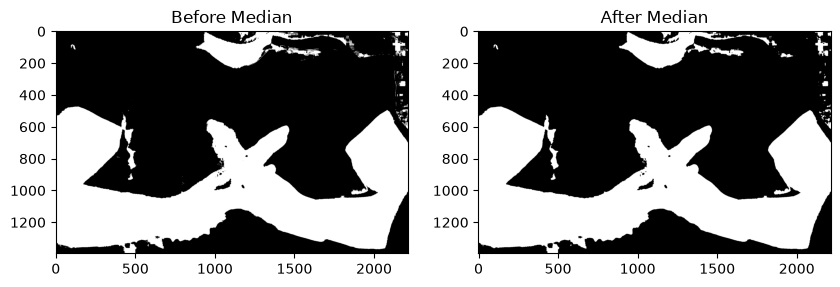

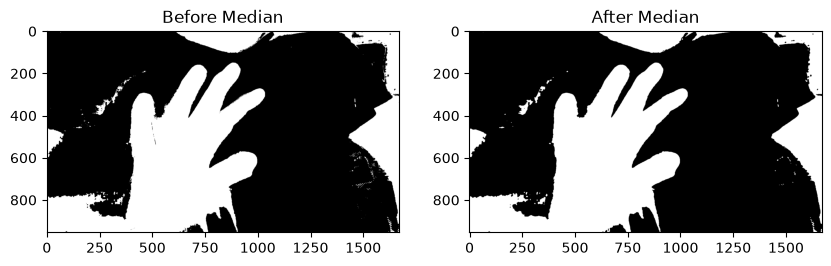

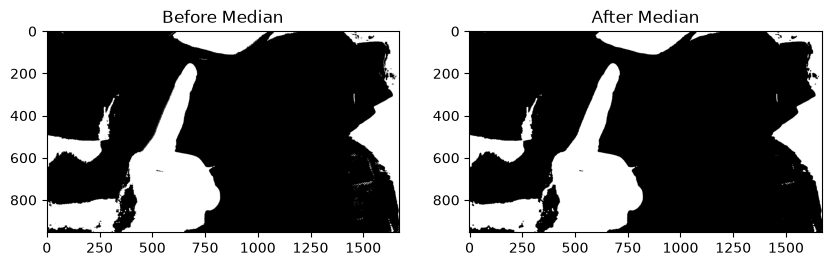

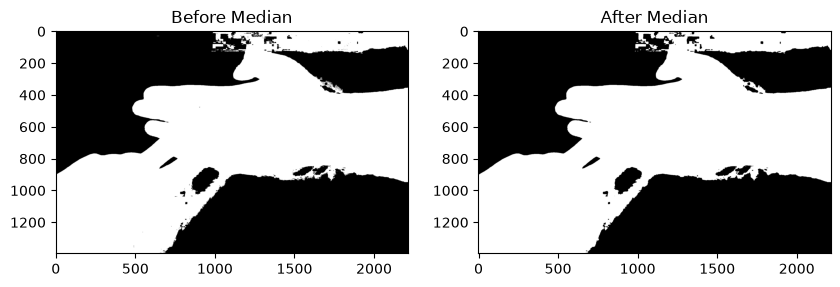

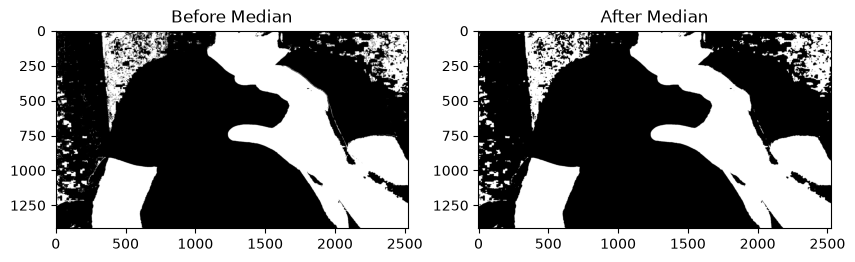

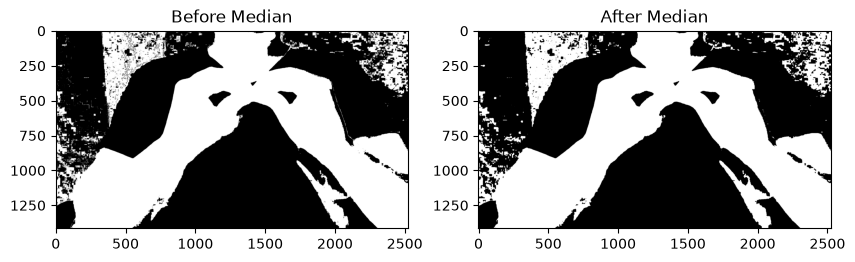

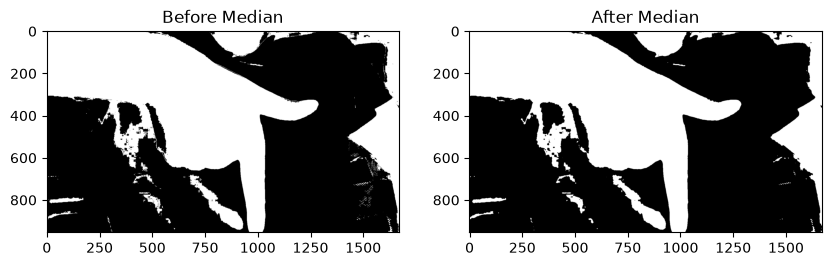

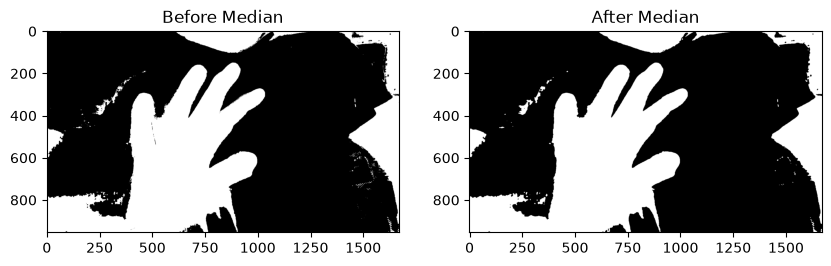

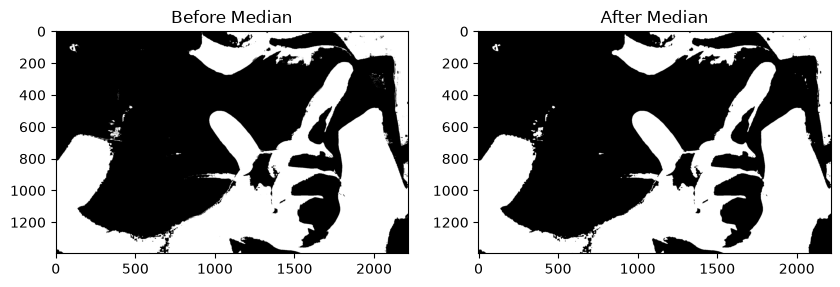

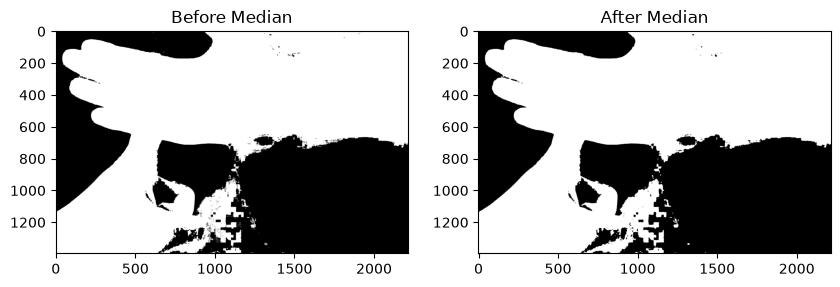

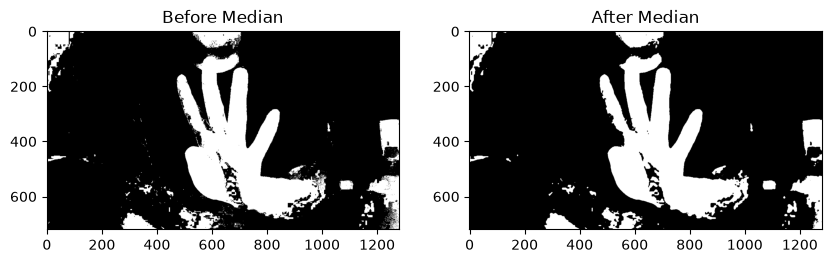

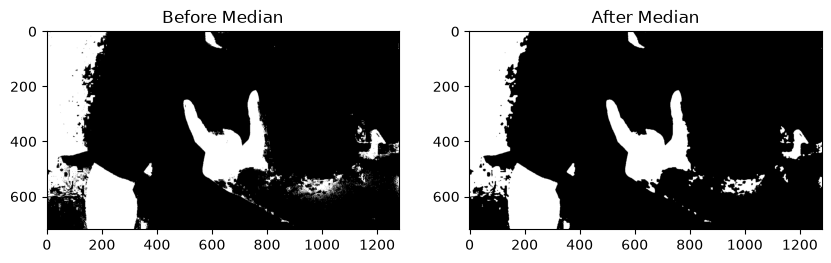

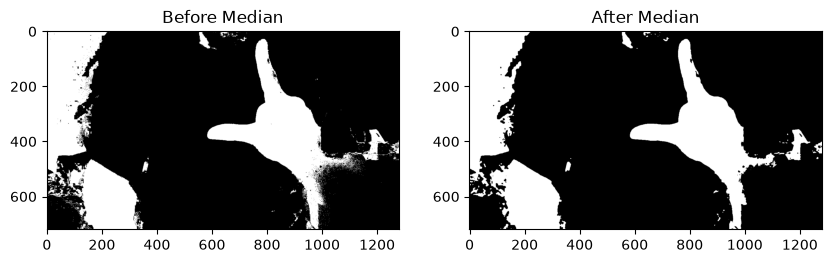

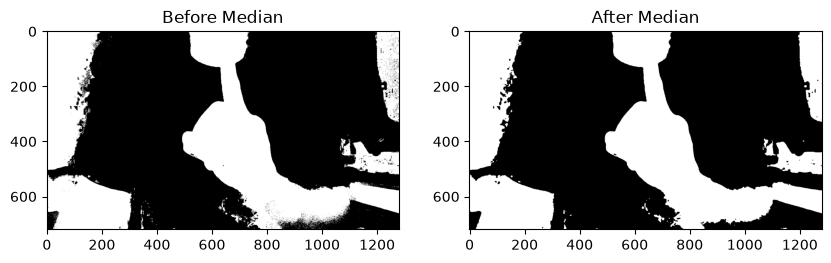

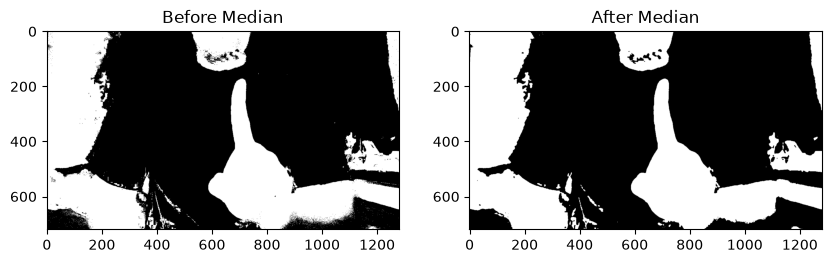

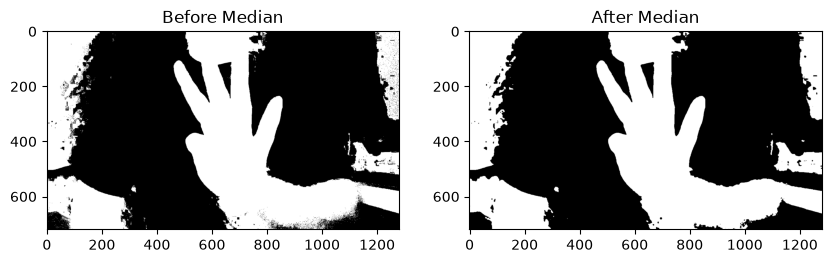

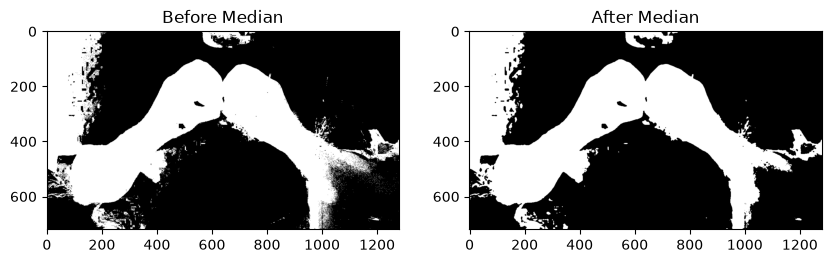

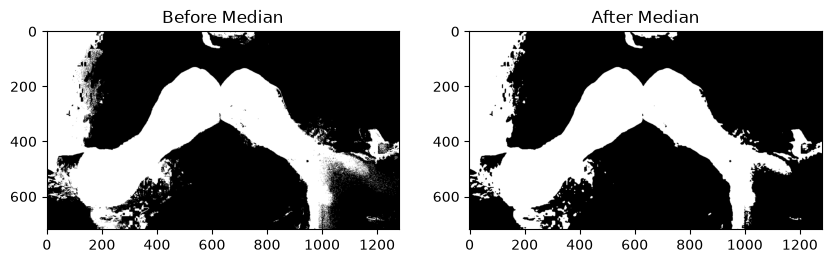

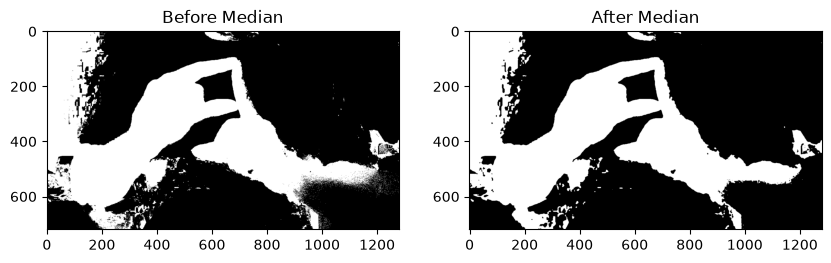

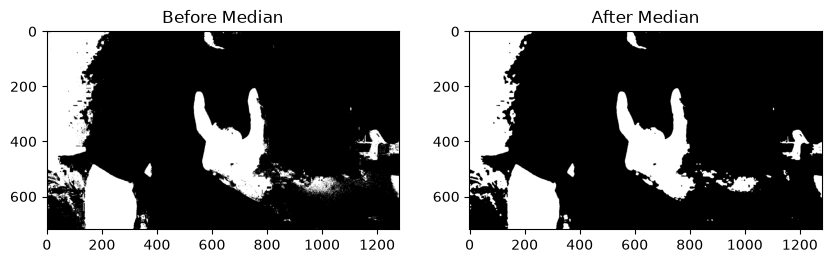

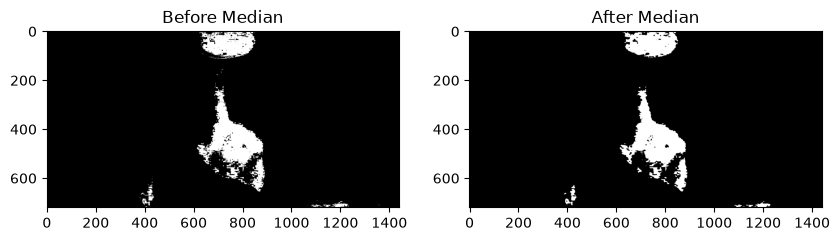

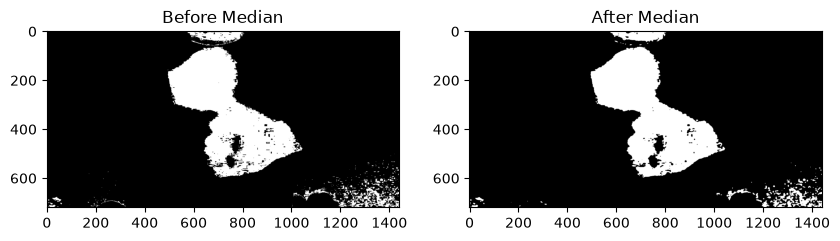

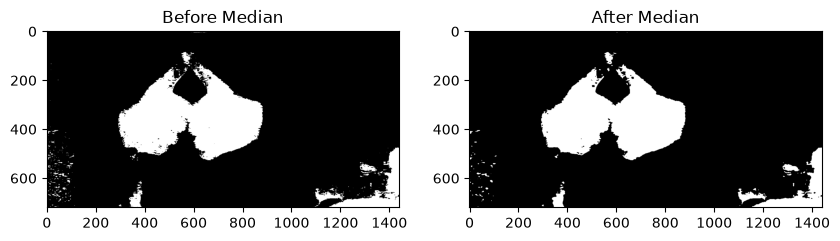

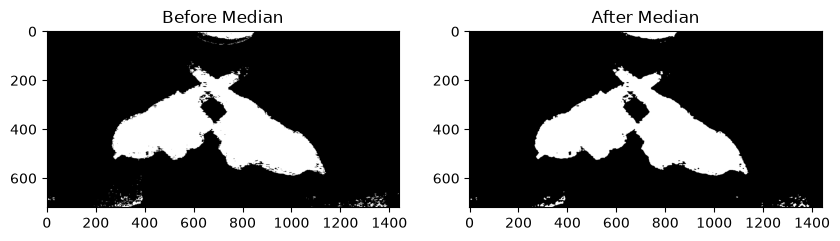

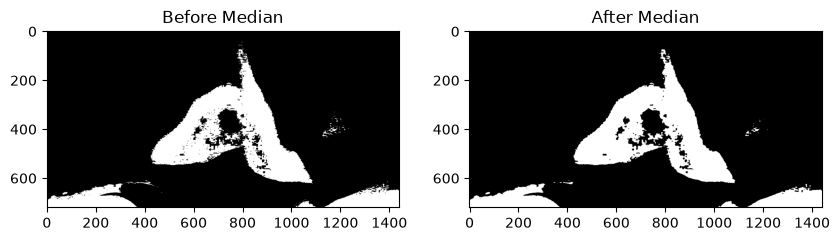

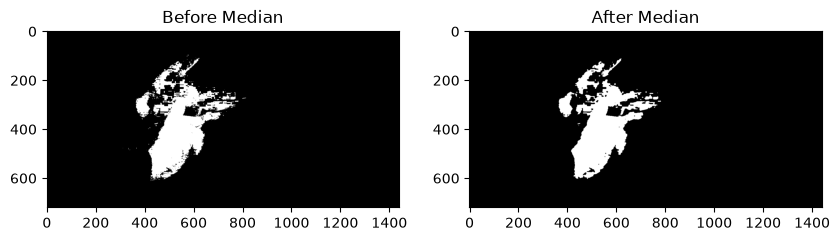

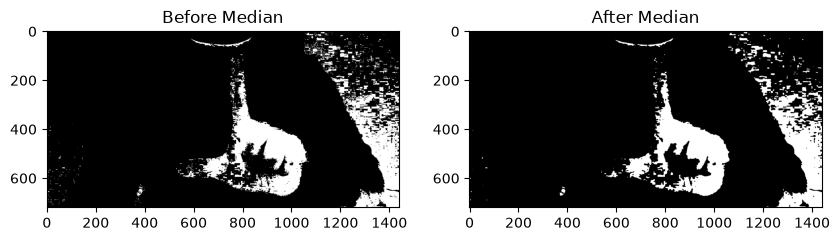

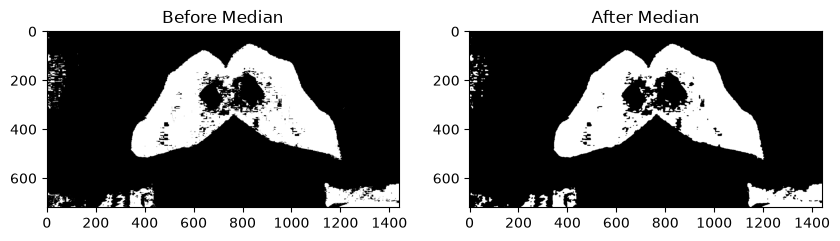

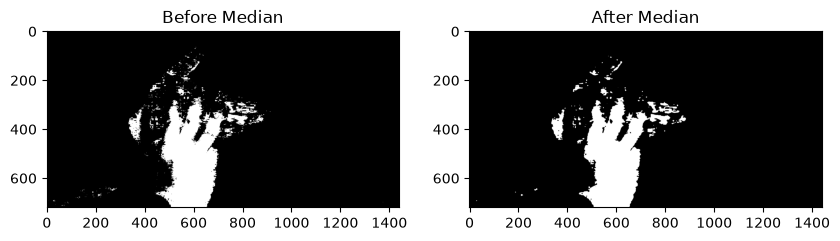

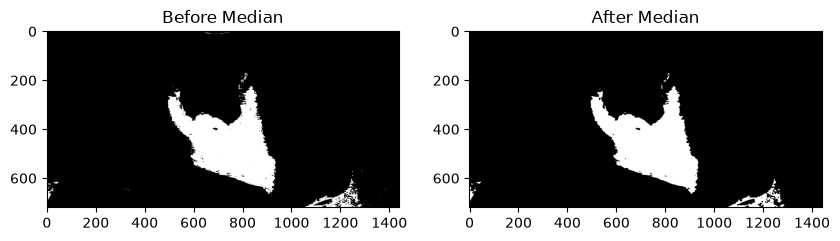

In [2]:
for path in sample_paths:

    image = read_image(path)

    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    mask = cv2.inRange(hsv, LOWER, UPPER)
    median = cv2.medianBlur(mask, 5)
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(mask, cmap="gray")
    plt.title("Before Median")

    plt.subplot(1, 2, 2)
    plt.imshow(median, cmap="gray")
    plt.title("After Median")

    plt.show()